# Exploratory data-analysis

## Imports

In [14]:
import pandas as pd
import matplotlib.pyplot as plt


## Load- & clean data

In [15]:
data = pd.read_csv("../data/raw/turbine_5yr.csv")

data.info()

<class 'pandas.DataFrame'>
RangeIndex: 262800 entries, 0 to 262799
Data columns (total 8 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   timestamp             262800 non-null  str    
 1   gearbox_oil_temp      262800 non-null  float64
 2   gearbox_bearing_temp  262800 non-null  float64
 3   vibration_x           262800 non-null  float64
 4   vibration_y           262800 non-null  float64
 5   vibration_z           262800 non-null  float64
 6   oil_pressure          262800 non-null  float64
 7   particle_count        262800 non-null  int64  
dtypes: float64(6), int64(1), str(1)
memory usage: 20.8 MB


In [16]:
# Fix column type
data["timestamp"] = pd.to_datetime(data["timestamp"])
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 262800 entries, 0 to 262799
Data columns (total 8 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   timestamp             262800 non-null  datetime64[us]
 1   gearbox_oil_temp      262800 non-null  float64       
 2   gearbox_bearing_temp  262800 non-null  float64       
 3   vibration_x           262800 non-null  float64       
 4   vibration_y           262800 non-null  float64       
 5   vibration_z           262800 non-null  float64       
 6   oil_pressure          262800 non-null  float64       
 7   particle_count        262800 non-null  int64         
dtypes: datetime64[us](1), float64(6), int64(1)
memory usage: 16.0 MB


In [17]:
# Check for missing values
data.isna().sum()

timestamp               0
gearbox_oil_temp        0
gearbox_bearing_temp    0
vibration_x             0
vibration_y             0
vibration_z             0
oil_pressure            0
particle_count          0
dtype: int64

## Exploring variable time series & distribution plots

Let's plot all variables against time.

In [18]:
x = data["timestamp"]

# All of the other columns
Y = data.drop(columns=["timestamp"])

In [19]:
x.head()

0   2025-01-01 00:00:00
1   2025-01-01 00:10:00
2   2025-01-01 00:20:00
3   2025-01-01 00:30:00
4   2025-01-01 00:40:00
Name: timestamp, dtype: datetime64[us]

In [20]:
Y.head()

,gearbox_oil_temp,gearbox_bearing_temp,vibration_x,vibration_y,vibration_z,oil_pressure,particle_count
0,59.24,65.85,0.0109,0.0092,0.0130,4.53,100
1,60.12,66.83,0.0076,0.0065,0.0092,4.48,100
2,59.50,65.16,0.0160,0.0136,0.0193,4.53,100
3,60.28,65.80,0.0164,0.0140,0.0197,4.54,100
4,60.72,66.84,0.0177,0.0151,0.0213,4.49,100


### Plotting the time series

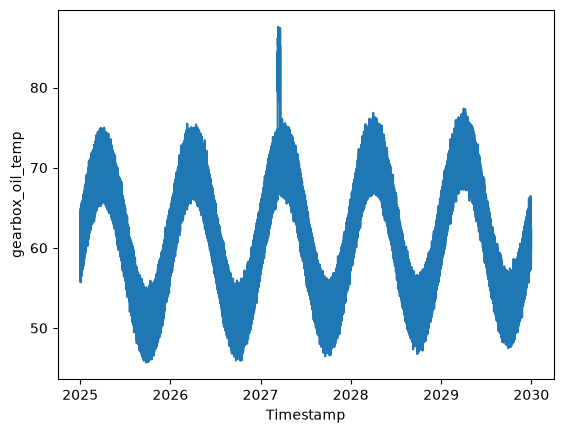

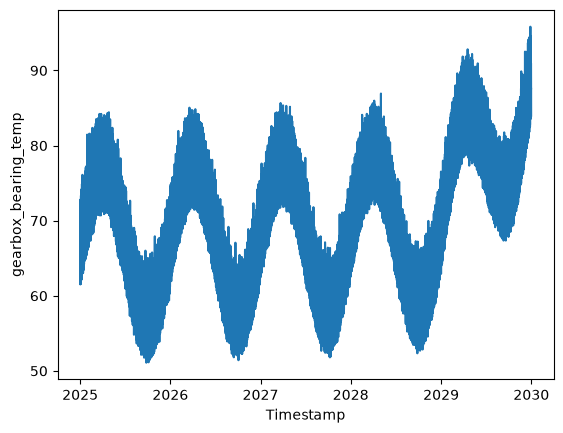

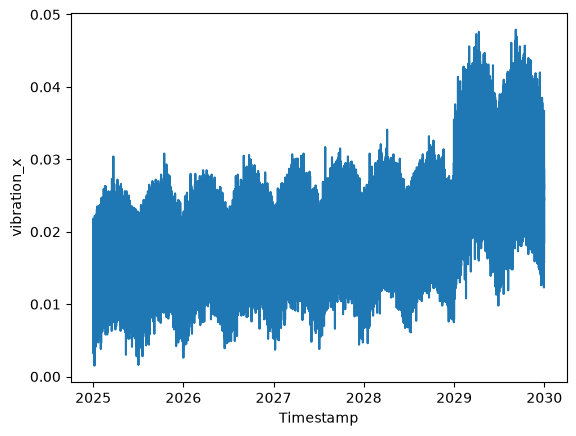

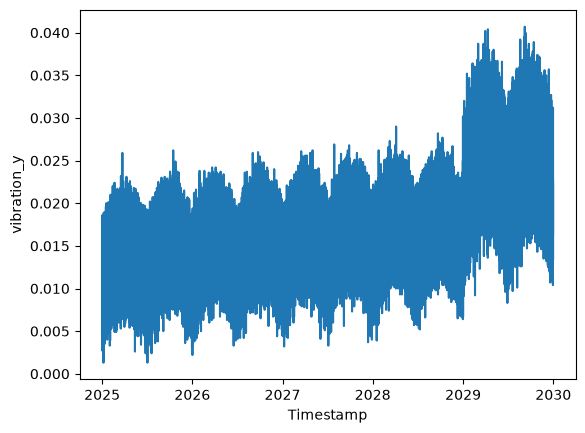

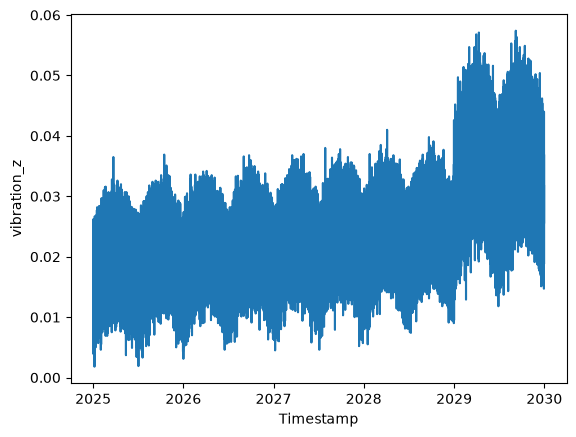

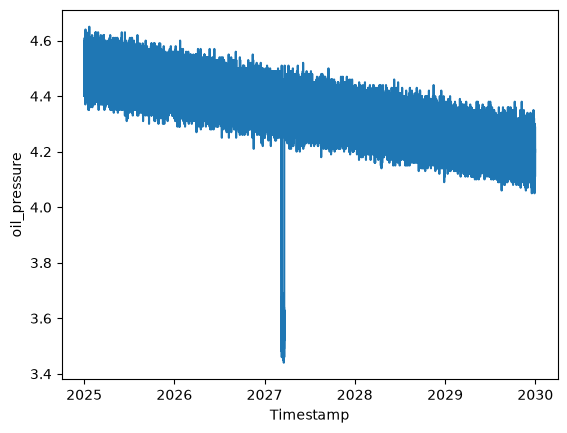

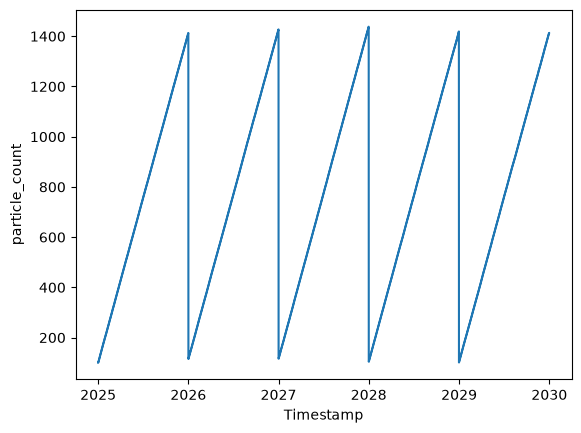

In [21]:
for colname in Y.columns:
    plt.plot(x, Y[colname])
    plt.xlabel("Timestamp")
    plt.ylabel(colname)
    plt.show()
    

### Plotting the distributions

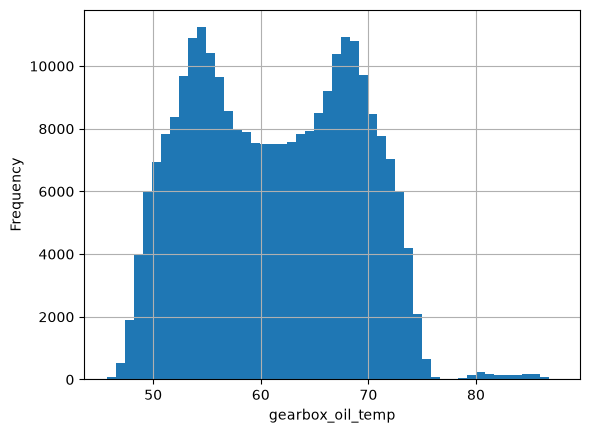

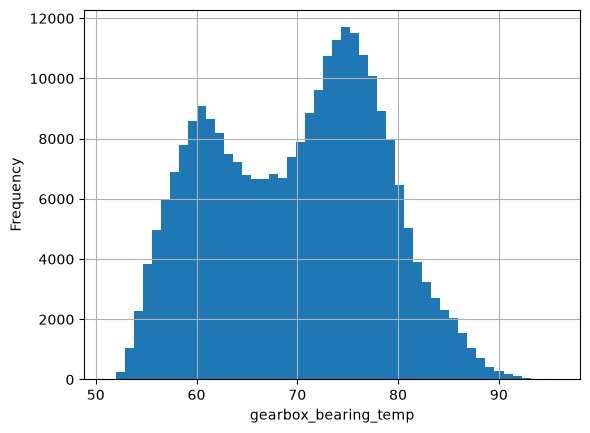

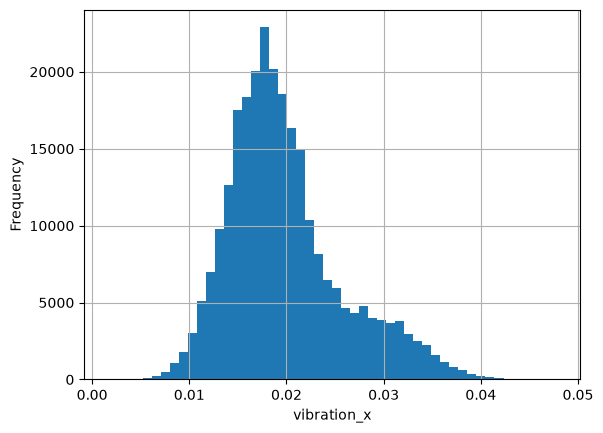

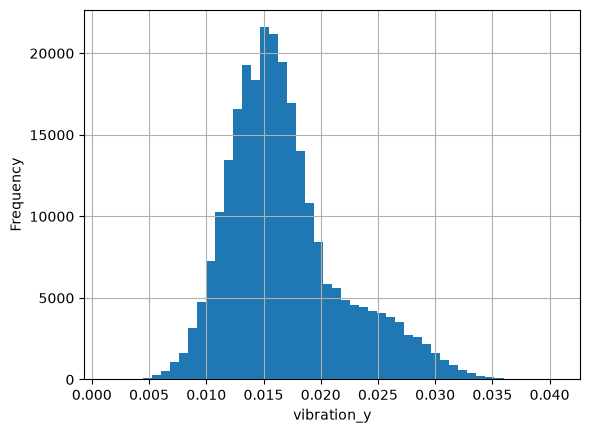

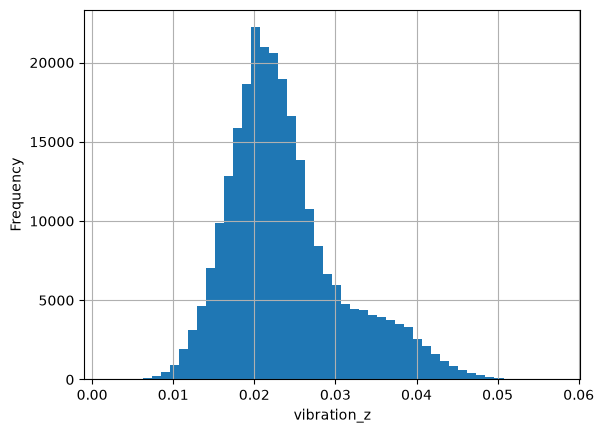

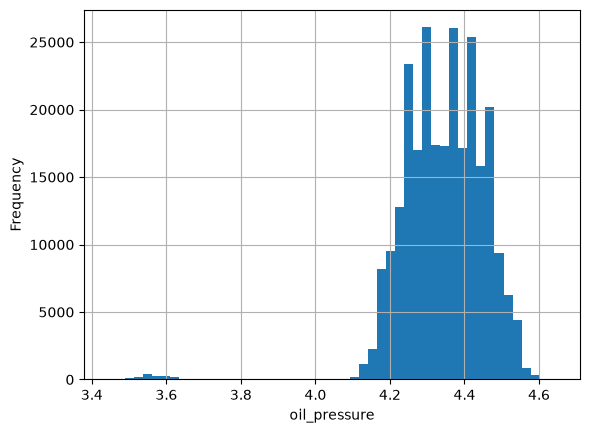

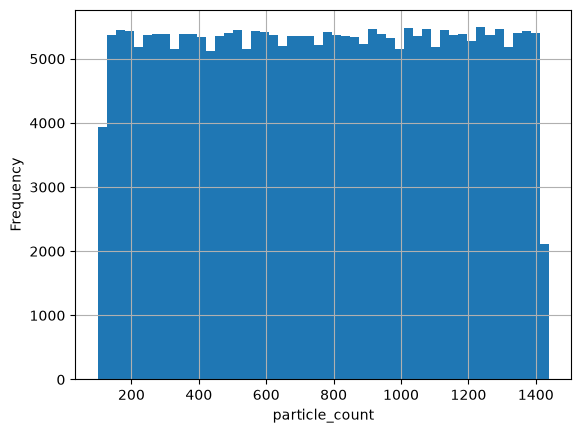

In [22]:
for colname in Y.columns:
    Y[colname].hist(bins=50)
    plt.xlabel(colname)
    plt.ylabel("Frequency")
    plt.show()
    

## Save processed data

In [23]:
data.to_parquet("../data/processed/turbine_cleaned.parquet", index=False)